# TS02 — Endpoint polynomial, spline, IIR and Kalman filters

## Goal
Compare causal endpoint estimators, quantify revision hazards, and evaluate both
forecast tracks. Match fixed linear filters on IID observation-noise variance gain
where feasible. Adaptive/time-varying Kalman output is reported separately.

## Observed results

The six fixed linear estimators have IID noise gains within **1.60%** of the EMA reference. Matched endpoint SG has **35.3%** step overshoot, versus **0.49%** for Bessel. The archived causal endpoints have exactly zero revision when later observations are appended. These tradeoffs are parameter- and noise-model-specific; Kalman is shown separately without attenuation matching.

## Setup
Use fixed parameters, trailing windows, forward IIR state and a filtered local linear
trend. No centered smoother enters a forecast feature or target. The spline uses
fixed lambda in session coordinates; cached endpoint weights exactly implement that
linear trailing spline fit. This is not automatic GCV selection.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'tslab').is_dir())
sys.path.insert(0, str(ROOT/'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tslab.smoothing import FilterSpec, CausalSmoother, smooth
from tslab.data import synthetic_signal, load_snapshot
from tslab.targets import make_targets, mature_labels
from tslab.evaluation import benchmark, scorecard, paired_block_difference
from tslab.diagnostics import audit_replay, response_metrics, latent_scores, impulse_response
from tslab.reporting import configure_plots, save_figure, write_manifest, filter_configs
configure_plots()
COLORS = dict(zip(['Unfiltered','EMA','DEMA','TEMA','KAMA','Butterworth','Bessel',
                  'Endpoint SG','Weighted local linear','Trailing spline','Kalman (unmatched)'],
                 ['#777777','#0072B2','#D55E00','#009E73','#CC79A7','#E69F00','#56B4E9',
                  '#AA4499','#332288','#882255','#117733']))
SEED = 1731
OUT = ROOT/'outputs'/'TS02_Endpoint_and_State_Space_Filters'
OUT.mkdir(parents=True, exist_ok=True)

### Estimator definitions
Trailing polynomial regression fits $p(u)=\sum_{j=0}^d\beta_j u^j$ at session
coordinates $u=-(w-1),\ldots,0$ and emits $p(0)=\beta_0$. Endpoint SG uses equal
weights and degree two here. The local-linear comparison uses degree one and
recency weights $1,\ldots,w$. Neither uses observations beyond the current endpoint.

The trailing spline minimizes
$$\sum_{i=1}^w[x_i-f(i)]^2+\lambda\int[f''(u)]^2\,du.$$
It emits the last fitted value, with fixed $\lambda$ in session coordinates.
Butterworth and Bessel use forward-only second-order sections; a saved state
carries the previous filter memory into each new observation. Bessel uses magnitude
normalization at the -3 dB cutoff, rather than a phase-normalized cutoff.

The Kalman model is
$$x_t=[1\;0]z_t+\epsilon_t,\qquad
z_t=\begin{bmatrix}1&1\\0&1\end{bmatrix}z_{t-1}+\eta_t,$$
with $z_t=(level_t,slope_t)$, $Q=\mathrm{diag}(10^{-5},10^{-7})$ and $R=10^{-4}$.
Initialize $z_0=(x_0,0)$ and $P_0=\mathrm{diag}(R,R)$. Only forward filtering is
performed. These fixed log-unit variances are illustrative rather than fitted market estimates.

## Steps
### 1. Match attenuation using filter mathematics
The reference EMA has $\alpha=0.2$, with IID observation-noise gain $\alpha/(2-\alpha)$.
Choose Butterworth/Bessel cutoffs by deterministic root solving, and trailing polynomial
windows or spline penalties from declared grids. This uses no market outcomes.
Matching one scalar does not match the full frequency response or prove equal forecast difficulty.

In [2]:
from scipy.optimize import brentq
from scipy.signal import savgol_filter
from scipy.interpolate import make_smoothing_spline
target_gain = .2/1.8
def gain(spec):
    kernel = impulse_response(spec)
    return float(kernel@kernel)
specs = {'EMA':FilterSpec(kind='ema',alpha=.2)}
for name,kind in [('Butterworth','butter'),('Bessel','bessel')]:
    cutoff = brentq(lambda c:gain(FilterSpec(kind=kind,cutoff=c))-target_gain,.002,.3)
    specs[name] = FilterSpec(kind=kind,cutoff=float(cutoff))
for name,kind in [('Endpoint SG','sg'),('Weighted local linear','local_linear')]:
    candidates = [FilterSpec(kind=kind,window=w) for w in range(11,122,2)]
    specs[name] = min(candidates,key=lambda p:abs(gain(p)-target_gain))
spline_candidates = [FilterSpec(kind='spline',window=81,lam=float(lam)) for lam in np.logspace(0,6,31)]
specs['Trailing spline'] = min(spline_candidates,key=lambda p:abs(gain(p)-target_gain))
kalman = FilterSpec(kind='kalman',q_level=1e-5,q_slope=1e-7,r=1e-4)
summary = pd.DataFrame([{'filter':name,**response_metrics(spec)[0],
    'relative_gain_mismatch':gain(spec)/target_gain-1,'window':spec.window,'cutoff':spec.cutoff,'lam':spec.lam}
    for name,spec in specs.items()])
summary.to_csv(OUT/'matched_filter_metrics.csv',index=False)
display(summary.round(5))

,filter,dc_gain,white_noise_gain,low_frequency_delay,overshoot_fraction,settling_2pct_sessions,relative_gain_mismatch,window,cutoff,lam
0,EMA,1.0,0.11111,4.00000,0.00000,17,0.00000,21,0.05000,20.00000
1,Butterworth,1.0,0.11111,4.40754,0.04475,19,0.00000,21,0.05064,20.00000
2,Bessel,1.0,0.11111,4.37228,0.00489,11,0.00000,21,0.04917,20.00000
3,Endpoint SG,1.0,0.11102,-0.00000,0.35257,76,-0.00086,77,0.05000,20.00000
4,Weighted local linear,1.0,0.11093,-0.00000,0.23256,37,-0.00162,41,0.05000,20.00000
5,Trailing spline,1.0,0.11288,-0.00000,0.19202,43,0.01596,81,0.05000,6309.57344


### 2. Compare common-target denoising and response distortion
Latent RMSE uses the same known latent signal and dates for every estimator. Unlike
cross-filter smoothed-target RMSE, this is a common-target comparison. Parameters are
matched on the declared IID-noise criterion, not optimized on this latent realization.
Kalman settings are illustrative and not attenuation matched.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS02_Endpoint_and_State_Space_Filters/02_response_and_overshoot.png')


,filter,n,latent_RMSE
0,EMA,550,0.009146
1,Butterworth,550,0.010596
2,Bessel,550,0.010279
3,Endpoint SG,550,0.025937
4,Weighted local linear,550,0.012009
5,Trailing spline,550,0.011941
6,Kalman (unmatched),550,0.006604


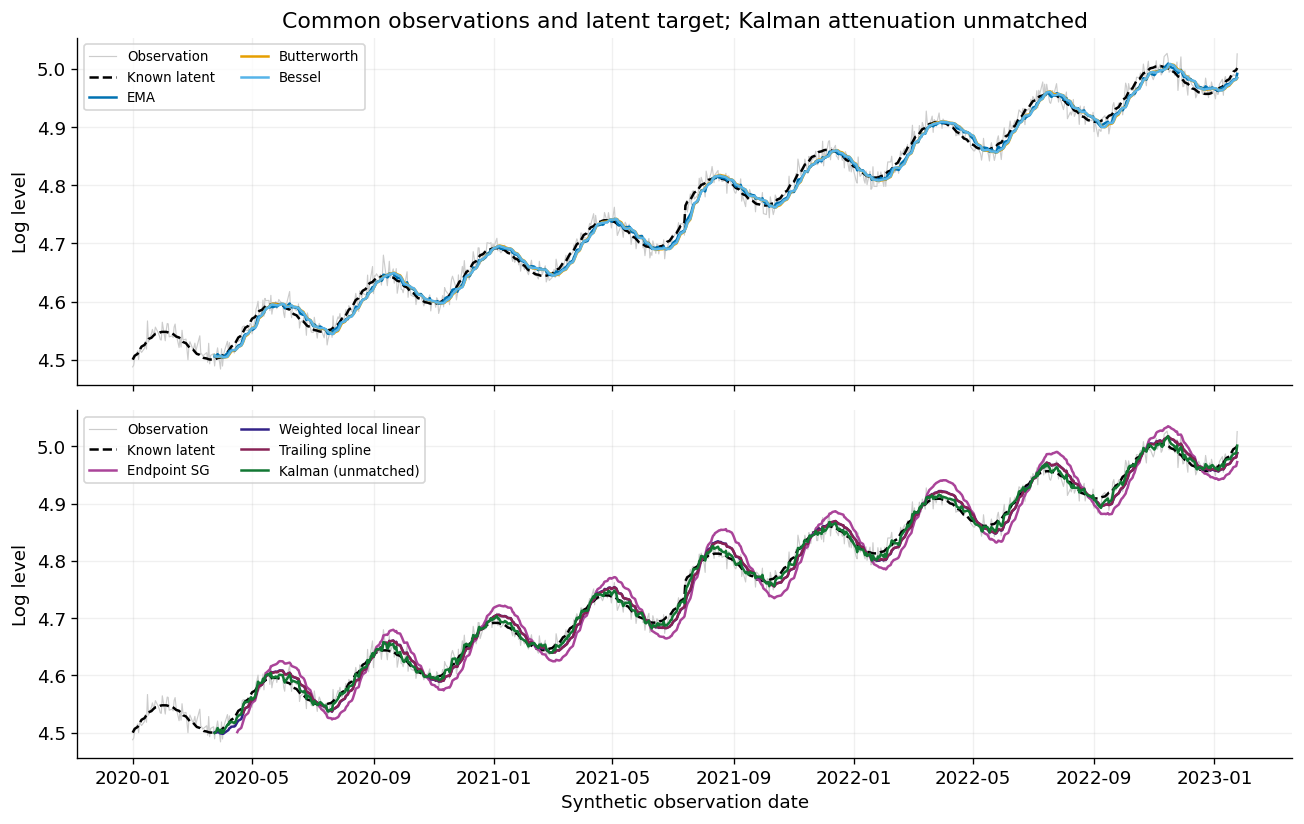

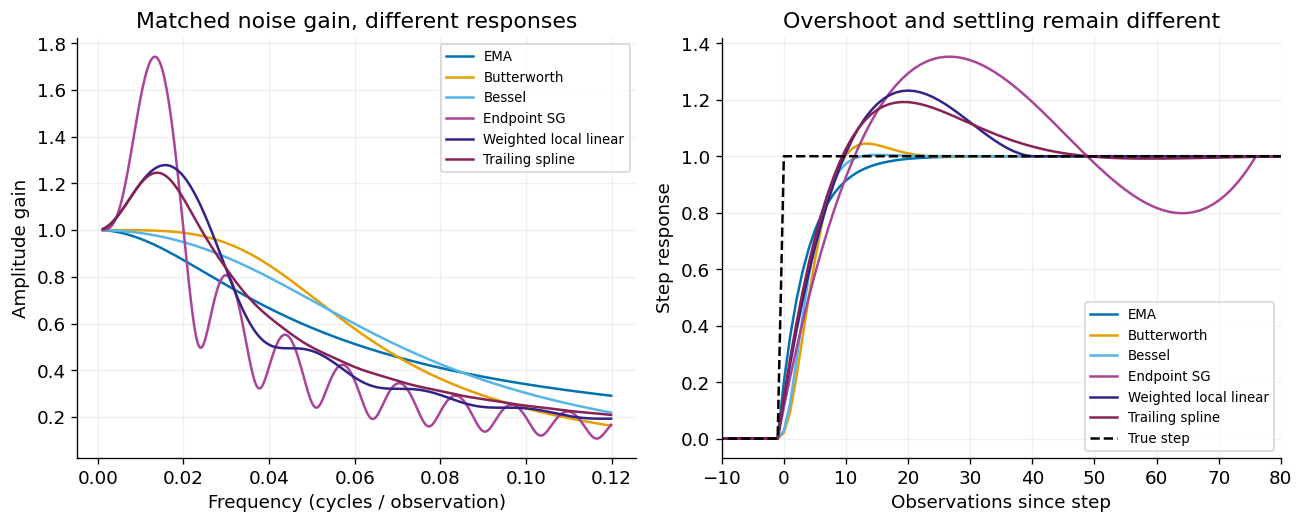

In [3]:
demo = synthetic_signal(seed=SEED)
all_specs = {**specs,'Kalman (unmatched)':kalman}
endpoints = pd.DataFrame({name:smooth(demo.observed,spec) for name,spec in all_specs.items()},index=demo.index)
latent = latent_scores(demo.observed,demo.latent,all_specs,start=250)
latent.to_csv(OUT/'common_latent_scores.csv',index=False)
endpoints.to_csv(OUT/'causal_endpoints.csv',index_label='Date')
display(latent.round(6))
fig, axes = plt.subplots(2,1,figsize=(11,7),sharex=True)
for ax,names in zip(axes,[['EMA','Butterworth','Bessel'],['Endpoint SG','Weighted local linear','Trailing spline','Kalman (unmatched)']]):
    ax.plot(demo.index,demo.observed,color='.8',lw=.7,label='Observation')
    ax.plot(demo.index,demo.latent,'k--',label='Known latent')
    for name in names:
        ax.plot(endpoints.index,endpoints[name],color=COLORS[name],label=name)
    ax.set_ylabel('Log level'); ax.legend(fontsize=8,ncol=2)
axes[0].set_title('Common observations and latent target; Kalman attenuation unmatched')
axes[-1].set_xlabel('Synthetic observation date')
save_figure(fig, OUT, '01_matched_endpoint_trajectories');
fig, axes = plt.subplots(1,2,figsize=(11,4.5))
step = np.r_[np.zeros(250),np.ones(150)]
for name,spec in specs.items():
    _,(f,H,delay) = response_metrics(spec)
    keep = (f>=.001)&(f<=.12)
    axes[0].plot(f[keep],np.abs(H[keep]),color=COLORS[name],label=name)
    axes[1].plot(np.arange(len(step))-250,smooth(step,spec),color=COLORS[name],label=name)
axes[0].set(xlabel='Frequency (cycles / observation)',ylabel='Amplitude gain',title='Matched noise gain, different responses')
axes[1].plot(np.arange(len(step))-250,step,'k--',label='True step')
axes[1].set(xlim=(-10,80),xlabel='Observations since step',ylabel='Step response',title='Overshoot and settling remain different')
for ax in axes:
    ax.legend(fontsize=8)
save_figure(fig, OUT, '02_response_and_overshoot');

### 3. Expose historical revision from retrospective smoothing
Compare outputs at the same historical dates before and after appending observations.
Centered SG and a whole-prefix spline curve revise interior history; archived causal
endpoints do not. A spline evaluated only at each then-current endpoint is a different
time series from the interior curve fitted later.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS02_Endpoint_and_State_Space_Filters/03_historical_revision.png')


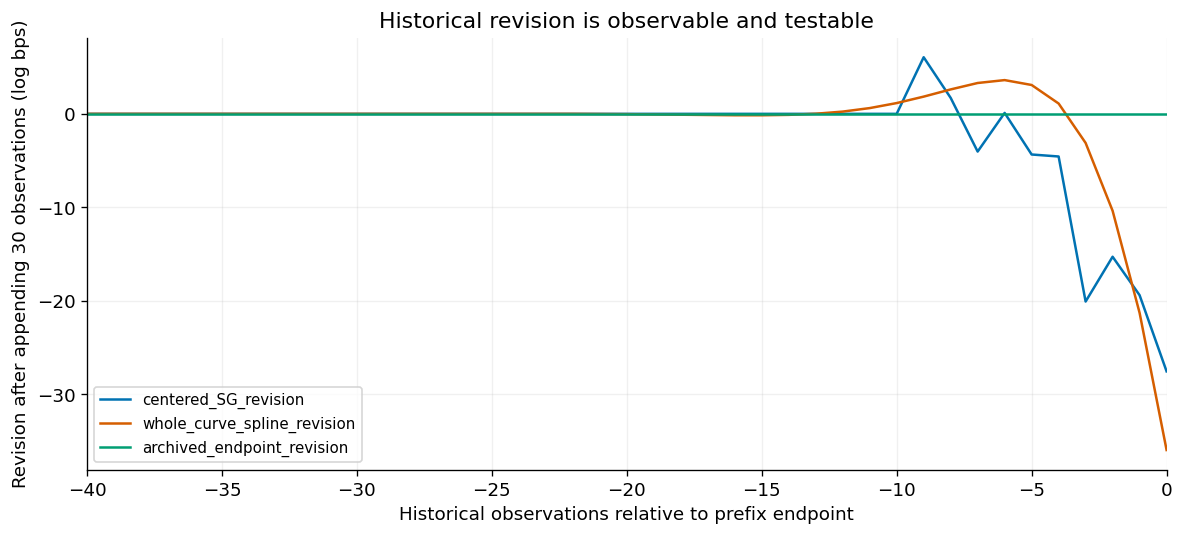

In [4]:
cut = 450
raw = demo.observed.to_numpy()
sg_prefix = savgol_filter(raw[:cut],21,2)
sg_later = savgol_filter(raw[:cut+30],21,2)[:cut]
times = np.arange(cut,dtype=float)
spline_prefix = make_smoothing_spline(times,raw[:cut],lam=20)(times)
spline_later = make_smoothing_spline(np.arange(cut+30,dtype=float),raw[:cut+30],lam=20)(times)
causal_prefix = smooth(raw[:cut],specs['Endpoint SG'])
causal_later = smooth(raw[:cut+30],specs['Endpoint SG'])[:cut]
revision = pd.DataFrame({'position':np.arange(cut),
    'centered_SG_revision':sg_later-sg_prefix,
    'whole_curve_spline_revision':spline_later-spline_prefix,
    'archived_endpoint_revision':causal_later-causal_prefix})
revision.to_csv(OUT/'historical_revision.csv',index=False)
assert np.nanmax(np.abs(revision.archived_endpoint_revision)) == 0
fig, ax = plt.subplots()
for name in ['centered_SG_revision','whole_curve_spline_revision','archived_endpoint_revision']:
    ax.plot(revision.position-cut+1,revision[name]*1e4,label=name)
ax.set(xlim=(-40,0),xlabel='Historical observations relative to prefix endpoint',
       ylabel='Revision after appending 30 observations (log bps)',title='Historical revision is observable and testable')
ax.legend(fontsize=9)
save_figure(fig, OUT, '03_historical_revision');

### 4. Compare the two forecast tracks without selecting a winner
Same historical SPY snapshot and scheduled origins as TS01. Endpoint settings are
fixed independently of market forecast outcomes. Smoothed track skill is relative
to each filter's own unchanged-path baseline; return track skill uses a common zero-return baseline.
Kalman path propagation remains a scenario for the operational filtered output; a
latent-state forecast is a different target and is outside this milestone.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS02_Endpoint_and_State_Space_Filters/04_separate_historical_skill.png')


,filter_id,model,n,RMSE,MSE_skill
31,Bessel,filter_drift,339,0.00905,-0.06500
32,Bessel,filter_nochange,339,0.00877,0.00000
33,Bessel,persistence,339,0.01773,-3.08841
34,Bessel,smooth_slope,339,0.01304,-1.21308
66,Butterworth,filter_drift,339,0.00764,-0.06221
67,Butterworth,filter_nochange,339,0.00741,0.00000
68,Butterworth,persistence,339,0.01800,-4.90082
69,Butterworth,smooth_slope,339,0.01242,-1.80849
101,EMA,filter_drift,339,0.01312,-0.09129
102,EMA,filter_nochange,339,0.01256,0.00000


,filter_id,model,n,RMSE,MSE_skill
12,Bessel,raw_drift,339,0.02731,-0.10676
13,Bessel,smooth_slope,339,0.03102,-0.42853
14,Bessel,zero,339,0.02596,0.00000
47,Butterworth,raw_drift,339,0.02731,-0.10676
48,Butterworth,smooth_slope,339,0.03081,-0.40941
49,Butterworth,zero,339,0.02596,0.00000
82,EMA,raw_drift,339,0.02731,-0.10676
83,EMA,smooth_slope,339,0.03281,-0.59824
84,EMA,zero,339,0.02596,0.00000
117,Endpoint SG,raw_drift,339,0.02731,-0.10676


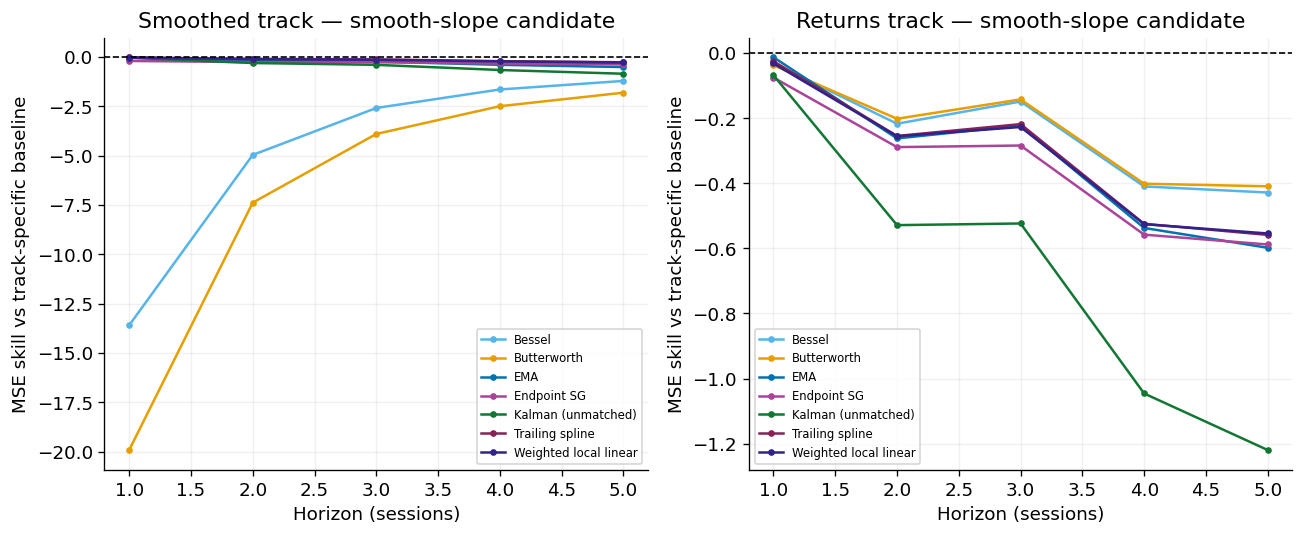

In [5]:
market_x,metadata = load_snapshot(ROOT/'inputs'/'SPY_adjusted_demo.csv',
                                 ROOT/'inputs'/'SPY_adjusted_demo.metadata.json')
frames = []
for name,spec in all_specs.items():
    result,_ = benchmark(market_x,spec,start=500,step=5,filter_id=name)
    frames.append(result)
records = pd.concat(frames,ignore_index=True)
scores = scorecard(records)
records.to_csv(OUT/'historical_forecasts.csv',index=False)
for track in ['smoothed','returns']:
    scores[scores.track==track].to_csv(OUT/f'{track}_scorecard.csv',index=False)
    display(scores.query('track==@track and horizon==5')[['filter_id','model','n','RMSE','MSE_skill']].round(5))
fig,axes = plt.subplots(1,2,figsize=(11,4.6))
for ax,track in zip(axes,['smoothed','returns']):
    for name,part in scores[(scores.track==track)&(scores.model=='smooth_slope')].groupby('filter_id'):
        ax.plot(part.horizon,part.MSE_skill,marker='o',ms=3,color=COLORS[name],label=name)
    ax.axhline(0,color='black',ls='--',lw=1)
    ax.set(title=f'{track.title()} track — smooth-slope candidate',xlabel='Horizon (sessions)',
           ylabel='MSE skill vs track-specific baseline'); ax.legend(fontsize=7)
save_figure(fig, OUT, '04_separate_historical_skill');

### 5. Quantify dependence-aware uncertainty for one predeclared comparison
Compare the EMA smooth-slope return candidate with zero at horizon five. Moving-block
resampling uses **scheduled origins**, not individual sessions. Show block-length
sensitivity rather than selecting the most favorable interval. The percentile ranges
are exploratory and conditional on this fixed design, not multiplicity-adjusted claims.

In [6]:
ema_records = records[records.filter_id=='EMA']
uncertainty = pd.DataFrame([paired_block_difference(ema_records,'returns','smooth_slope','zero',
    horizon=5,block=b,draws=1000,seed=SEED) for b in [5,10,20]])
uncertainty.to_csv(OUT/'paired_block_sensitivity.csv',index=False)
display(uncertainty.round(6))

,mean_MAE_difference,lower95,upper95,n_origins,block_origins,draws
0,0.004955,0.003502,0.006480,339,5,1000
1,0.004955,0.003549,0.006466,339,10,1000
2,0.004955,0.003619,0.006291,339,20,1000


## Checks
Check all seven estimators independently, including checkpoint/resume and poisoned
future data. Every filter/model comparison retains its full scheduled origins,
including immature endpoint forecasts. Full unit tests also verify numerical references.

In [7]:
checks = pd.DataFrame([{'filter':name,**audit_replay(raw,spec)} for name,spec in all_specs.items()])
checks.to_csv(OUT/'replay_checks.csv',index=False)
assert scores.groupby(['filter_id','track','horizon']).n.nunique().eq(1).all()
assert (scores.groupby(['track','horizon']).n.nunique()==1).all()
display(checks)
write_manifest(OUT, {'filters':filter_configs(all_specs),'start':500,'step':5,
    'matching_target':'IID observation-noise gain alpha/(2-alpha), alpha=.2',
    'matching_uses_market_outcomes':False,'kalman_matched':False},metadata,seed=SEED)
print('PASS: causal replay, matched-origin and immutable-endpoint checks.')

PASS: causal replay, matched-origin and immutable-endpoint checks.


,filter,kind,prefix_invariant,future_poison_invariant,checkpoint_equivalent,projection_nonmutating
0,EMA,ema,True,True,True,True
1,Butterworth,butter,True,True,True,True
2,Bessel,bessel,True,True,True,True
3,Endpoint SG,sg,True,True,True,True
4,Weighted local linear,local_linear,True,True,True,True
5,Trailing spline,spline,True,True,True,True
6,Kalman (unmatched),kalman,True,True,True,True


## Next Steps
Milestone 1 establishes the contracts, filter mechanics and baseline scorecards.
TS03 will cover FFT/decomposition; TS04 will add classical forecasting. The shared
evaluation harness should be extended to nested chronological model selection there.
No filter or forecast candidate has been promoted to deployment status.

References: [endpoint SG](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.savgol_coeffs.html),
[smoothing splines](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.make_smoothing_spline.html),
[forward IIR](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.sosfilt.html),
[Bessel normalization](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.bessel.html).